# Plot compartment traces from HDF5

Reads the HDF5 file made by `organize_to_hdf5` and plots mean ± SEM traces in two ways:
- **Section 5:** one plot per condition, with the compartments overlaid (`plot_compartments_overlay_by_genotype_compactstyle`).
- **Section 7:** one plot per compartment, with the conditions overlaid (`plot_genotypes_overlay_compactstyle`).

Processing (sections 3, 4 and 6):
- each neuron's trace gets a time axis from the imaging frequency,
- it is low-pass filtered at its own imaging frequency (zero-phase Butterworth; the cutoff is set with `lowpass_cutoff_hz`, 10 Hz by default),
- the nearest filtered sample is taken at each point of a common time grid (`grid_step`, 20 ms by default), so flies imaged at different frequencies line up. There is no binning or averaging in this step,
- all neurons from all flies of a condition and compartment are pooled, and the mean and SEM are taken at each time point.

Data loading: `load_all_data_from_hdf5` reads the HDF5 file into a nested dictionary (`all_data`), grouping the flies by their `condition` metadata.

**How to use:** set `H5_FILE` in section 1, then run all cells.

In [21]:
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D
from scipy.signal import butter, sosfiltfilt

## 1. Settings

In [22]:
H5_FILE = Path("your/path/here/cc.h5")

compartment_colors = {
    "m1": "#440154",
    "m2": "#46327e",
    "m3": "#365c8d",
    "m5": "#277f8e",
    "m8": "#1fa187",
    "m9": "#4ac16d",
    "m10": "#a0da39",
    "lo1": "#fde725",
    "lo4": "#b8de29",
}

## 2. Load the data

In [23]:
def load_all_data_from_hdf5(h5_file):
    """
    Read the HDF5 file made by organize_to_hdf5 into a nested dictionary,
    grouping flies by their condition attribute:

    all_data = {
      '<condition>': {
        'folder': '<condition>',
        'series': {
          '251117_s7': {
            'frequency': <float or None>,
            'compartments': {
              'lo1': {'ca': DataFrame, 'hylight': DataFrame},   # rows = neurons, columns = time points
              ...
            }
          },
          ...
        }
      },
      ...
    }
    """
    all_data = {}
    with h5py.File(h5_file, "r") as f:
        for fly_id, fly in f.items():
            condition = fly.attrs["condition"]
            for compartment, comp in fly.items():
                folder_dict = all_data.setdefault(condition, {"folder": condition, "series": {}})
                sdict = folder_dict["series"].setdefault(
                    fly_id, {"frequency": None, "compartments": {}}
                )
                freq = float(comp.attrs.get("imaging_frequency", np.nan))
                if sdict["frequency"] is None and np.isfinite(freq):
                    sdict["frequency"] = freq

                comp_dict = sdict["compartments"].setdefault(compartment, {})
                for meas_type, dset in comp.items():
                    comp_dict[meas_type] = pd.DataFrame(dset[:])
    return all_data


def summarize_all_data(all_data):
    """Number of flies (series) and neurons per condition, compartment and sensor."""
    rows = []
    for condition, folder_dict in all_data.items():
        for series_key, sdict in folder_dict["series"].items():
            for compartment, meas in sdict["compartments"].items():
                for meas_type, df in meas.items():
                    rows.append({
                        "condition": condition,
                        "compartment": compartment,
                        "sensor": meas_type,
                        "series": series_key,
                        "n_neurons": df.shape[0],
                        "has_frequency": sdict["frequency"] is not None,
                    })
    df = pd.DataFrame(rows)
    if df.empty:
        return df
    return (df.groupby(["condition", "compartment", "sensor"])
              .agg(n_flies=("series", "nunique"),
                   n_neurons=("n_neurons", "sum"),
                   flies_without_frequency=("has_frequency", lambda s: int((~s).sum())))
              .reset_index())


def select_genotypes(all_data, genotypes=None):
    """
    Return all_data with only the listed conditions (genotypes).
    genotypes=None returns all conditions. Names must match exactly,
    including the special minus sign in names like "−Sugar".
    """
    if genotypes is None:
        return all_data
    if isinstance(genotypes, str):
        genotypes = [genotypes]
    missing = [g for g in genotypes if g not in all_data]
    if missing:
        print(f"Not found: {missing}. Available: {list(all_data)}")
    return {g: all_data[g] for g in genotypes if g in all_data}

In [24]:
all_data = load_all_data_from_hdf5(H5_FILE)
summarize_all_data(all_data)

,condition,compartment,sensor,n_flies,n_neurons,flies_without_frequency
0,postcc,m9,ca,10,46,0
1,postcc,m9,hylight,10,46,0
2,precc,m9,ca,6,21,0
3,precc,m9,hylight,6,21,0


## 3. Processing and plotting helpers
`_lowpass_filter_to_common_grid` filters each trace. The cutoff (`lowpass_cutoff_hz`), filter order (`filter_order`) and grid spacing (`grid_step`) are set in the plot calls in sections 5 and 7.

In [25]:
def _wide_df_to_trace_series_dict(df: pd.DataFrame, freq: float) -> dict[str, pd.Series]:
    """
    Interpret df as WIDE-TIME:
      rows = traces
      columns = time samples
    Return:
      {trace_name: pd.Series indexed by Timedelta}
    """
    if df is None or not isinstance(df, pd.DataFrame) or df.empty:
        return {}
    if freq is None or freq <= 0:
        return {}

    wide_vals = df.apply(pd.to_numeric, errors="coerce")
    n_traces, n_samples = wide_vals.shape
    if n_traces < 1 or n_samples < 2:
        return {}

    t = np.arange(n_samples, dtype=float) / float(freq)
    idx = pd.to_timedelta(t, unit="s")

    out = {}
    for i in range(n_traces):
        y = pd.to_numeric(wide_vals.iloc[i, :], errors="coerce").to_numpy()
        if np.all(np.isnan(y)):
            continue
        out[f"trace_{i+1}"] = pd.Series(y, index=idx)

    return out


def _lowpass_filter_to_common_grid(
    ts: pd.Series,
    lowpass_cutoff_hz: float = 10.0,
    filter_order: int = 4,
    grid_step: str = "20ms",
) -> pd.Series:
    """
    Low-pass filter one trace and return it on a common time grid.

    1. The trace is low-pass filtered at its own imaging frequency with a
       zero-phase Butterworth filter (scipy.signal.sosfiltfilt), so it is not
       shifted in time.
    2. At each grid time (0, grid_step, 2 x grid_step, ...) the nearest
       filtered sample is taken. Nothing is averaged. The grid only lines up
       flies imaged at different frequencies, so their traces can be averaged
       at the same time points.

    Missing values (NaN) are filled by linear interpolation only so that the
    filter can run; they are set back to NaN in the output.

    grid_step must be shorter than 1 / (2 x lowpass_cutoff_hz), for example
    shorter than 50 ms for a 10 Hz cutoff and shorter than 125 ms for 4 Hz.
    """
    t = ts.index.total_seconds().to_numpy()
    y = ts.to_numpy(dtype=float)

    fs = 1.0 / np.median(np.diff(t))
    step = pd.Timedelta(grid_step).total_seconds()

    if lowpass_cutoff_hz >= fs / 2:
        raise ValueError(
            f"lowpass_cutoff_hz={lowpass_cutoff_hz} must be below half the "
            f"imaging frequency ({fs / 2:.1f} Hz)."
        )
    if lowpass_cutoff_hz >= 1 / (2 * step):
        raise ValueError(
            f"grid_step={grid_step} is too coarse for lowpass_cutoff_hz={lowpass_cutoff_hz}; "
            f"use a step shorter than {1000 / (2 * lowpass_cutoff_hz):.0f} ms."
        )

    finite = np.isfinite(y)
    if not finite.any():
        grid = np.arange(0, t[-1] + 1e-9, step)
        return pd.Series(np.nan, index=pd.to_timedelta(grid, unit="s"))

    # Fill missing values so that the filter can run.
    y_filled = np.interp(t, t[finite], y[finite])

    # Zero-phase Butterworth low-pass filter at the original imaging frequency.
    sos = butter(filter_order, lowpass_cutoff_hz, btype="lowpass", fs=fs, output="sos")
    padlen = min(3 * (2 * len(sos) + 1), len(y_filled) - 1)
    y_filtered = sosfiltfilt(sos, y_filled, padlen=padlen)

    # Nearest sample at each grid time (samples are at t = i / fs).
    grid = np.arange(0, t[-1] + 1e-9, step)
    idx = np.clip(np.rint(grid * fs).astype(int), 0, len(y) - 1)
    values = np.where(finite[idx], y_filtered[idx], np.nan)

    return pd.Series(values, index=pd.to_timedelta(grid, unit="s"))

In [26]:
def _normalize_stim_type(stim_type: str) -> str:
    """
    Allow a few user-friendly aliases.
    """
    if stim_type is None:
        raise ValueError("stim_type cannot be None")

    s = str(stim_type).lower().strip()
    s = s.replace(" ", "").replace("_", "").replace("-", "")

    aliases = {
        "20xflicker": "20xflicker",
        "300msdark": "300ms-dark",
        "300mslight": "300ms-light",
    }

    if s not in aliases:
        raise ValueError(
            f"Unknown stim_type '{stim_type}'. "
            f"Supported values: '20xflicker', '300msdark', '300mslight'"
        )

    return aliases[s]


def _stimulus_segments(stim_type: str, stim_start: float = 1.0):
    """
    Return:
      segments = [(seg_start, seg_end, facecolor), ...]
      stim_end = end time of stimulus

    Rules:
      - 20xflicker = 4 s of 2 Hz light/dark flashes, starting with light
      - 300ms-dark = 300 ms dark flash
      - 300ms-light = 300 ms light flash
    """
    stim_type = _normalize_stim_type(stim_type)

    if stim_type == "20xflicker":
        total_duration = 4.0
        half_phase = 0.25   # alternating light/dark every 250 ms
        n_segments = int(round(total_duration / half_phase))

        segments = []
        for i in range(n_segments):
            seg_start = stim_start + i * half_phase
            seg_end = seg_start + half_phase
            seg_color = "white" if i % 2 == 0 else "black"   # starts with light
            segments.append((seg_start, seg_end, seg_color))

        stim_end = stim_start + total_duration
        return segments, stim_end

    if stim_type == "300ms-dark":
        return [(stim_start, stim_start + 0.3, "black")], stim_start + 0.3

    if stim_type == "300ms-light":
        return [(stim_start, stim_start + 0.3, "white")], stim_start + 0.3

    raise ValueError(f"Unsupported stim_type '{stim_type}'")

In [27]:
def _draw_footer_scale_bar(
    fig,
    ax,
    foot,
    t_anchor_data,
    df_over_f_scale=0.10,
    time_scale=0.5,
    x0=-0.03,
    y0=1.4,
    line_width=1.0,
    fontsize=9,
    df_label_prefix="",
):
    """
    Draw an L-shaped scale bar in a footer axis, with lengths matched
    to the main plot in display/pixel space.
    """
    foot.set_axis_off()
    foot.set_xlim(0, 1)
    foot.set_ylim(0, 1)
    foot.set_autoscale_on(False)

    fig.canvas.draw()

    to_disp = ax.transData.transform
    from_disp_footer = foot.transAxes.inverted().transform

    # Horizontal length in footer corresponding to time_scale in main axis
    p0x = to_disp((t_anchor_data, 0.0))
    p1x = to_disp((t_anchor_data + time_scale, 0.0))
    q0x = from_disp_footer(p0x)
    q1x = from_disp_footer(p1x)
    time_frac = q1x[0] - q0x[0]

    # Vertical length in footer corresponding to df_over_f_scale in main axis
    p0y = to_disp((t_anchor_data, 0.0))
    p1y = to_disp((t_anchor_data, df_over_f_scale))
    q0y = from_disp_footer(p0y)
    q1y = from_disp_footer(p1y)
    df_frac = q1y[1] - q0y[1]

    foot.add_line(Line2D(
        [x0, x0], [y0, y0 + df_frac],
        transform=foot.transAxes,
        lw=line_width,
        color="black",
        solid_capstyle="butt",
        clip_on=False
    ))

    foot.add_line(Line2D(
        [x0, x0 + time_frac], [y0, y0],
        transform=foot.transAxes,
        lw=line_width,
        color="black",
        solid_capstyle="butt",
        clip_on=False
    ))

    foot.text(
        x0 - 0.035,
        y0 + df_frac / 2,
        f"{df_label_prefix}{int(round(df_over_f_scale * 100))}%\nΔF/F",
        transform=foot.transAxes,
        ha="right",
        va="bottom",
        fontsize=fontsize
    )

    foot.text(
        x0 + time_frac / 2,
        y0 - 0.20,
        f"{time_scale} s",
        transform=foot.transAxes,
        ha="center",
        va="top",
        fontsize=fontsize
    )


def _style_compact_axis(
    ax,
    tmin,
    tmax,
    ylim,
    stim_type,
    stim_start=1.0,
    add_stim_background=True,
    stim_background_color="0.88",
    stim_background_alpha=1.0,
    background_bar_color="0.8",
):
    ax.set_xlim(tmin, tmax)
    ax.set_ylim(*ylim)

    for side in ("top", "right", "left", "bottom"):
        ax.spines[side].set_visible(False)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.tick_params(bottom=False, left=False)
    ax.grid(False)

    segments, stim_end = _stimulus_segments(stim_type, stim_start=stim_start)

    # gray stimulus-duration window behind the trace
    if add_stim_background:
        ax.axvspan(
            stim_start,
            stim_end,
            color=stim_background_color,
            alpha=stim_background_alpha,
            lw=0,
            zorder=0
        )

    # top header bar
    bar_ax = ax.inset_axes([0, 1.03, 1, 0.10], transform=ax.transAxes, clip_on=False)
    bar_ax.set_xlim(tmin, tmax)
    bar_ax.set_ylim(0, 1)

    # full background bar
    bar_ax.add_patch(Rectangle(
        (tmin, 0), tmax - tmin, 1,
        facecolor=background_bar_color,
        edgecolor="black",
        linewidth=0.9
    ))

    # draw stimulus pattern
    for seg_start, seg_end, seg_color in segments:
        bar_ax.add_patch(Rectangle(
            (seg_start, 0),
            seg_end - seg_start,
            1,
            facecolor=seg_color,
            edgecolor="none",
            linewidth=0
        ))

    # crisp outer border
    bar_ax.add_patch(Rectangle(
        (tmin, 0), tmax - tmin, 1,
        facecolor="none",
        edgecolor="black",
        linewidth=0.9
    ))

    bar_ax.axis("off")

## 4. Overlay compartments within each condition

In [28]:
# ============================================================
# Overlay compartments within each genotype
# ============================================================

def _get_case_insensitive(d: dict, key):
    """
    Safely get d[key], allowing case-insensitive matching.
    Useful if compartments are stored as 'M9' but you pass 'm9', etc.
    """
    if not isinstance(d, dict):
        return None

    if key in d:
        return d[key]

    key_lower = str(key).lower()
    for k, v in d.items():
        if str(k).lower() == key_lower:
            return v

    return None


def build_standardized_traces_by_genotype_and_compartment(
    all_data: dict,
    compartments,
    meas_type: str,
    lowpass_cutoff_hz: float = 10.0,
    filter_order: int = 4,
    grid_step: str = "20ms",
    dropna_all: bool = True,
) -> dict:
    """
    Convert nested all_data structure into low-pass-filtered traces
    on a common time grid (see _lowpass_filter_to_common_grid).

    Returns:
      standardized[genotype][compartment][series_key][trace_name] = pd.Series
    """

    if isinstance(compartments, str):
        compartments = [compartments]

    standardized = {}

    for genotype, folder_dict in all_data.items():
        series_map = folder_dict.get("series", {})
        genotype_out = {}

        for compartment in compartments:
            compartment_out = {}

            for series_key, sdict in series_map.items():
                freq = sdict.get("frequency", None)

                compartment_dict = sdict.get("compartments", {})
                this_compartment_data = _get_case_insensitive(compartment_dict, compartment)

                if this_compartment_data is None:
                    continue

                df = _get_case_insensitive(this_compartment_data, meas_type)

                if df is None or not isinstance(df, pd.DataFrame) or df.empty:
                    continue
                if freq is None or freq <= 0:
                    continue

                traces = _wide_df_to_trace_series_dict(df, float(freq))
                if not traces:
                    continue

                rs_traces = {}

                for tr_name, ts in traces.items():
                    try:
                        rs = _lowpass_filter_to_common_grid(
                            ts,
                            lowpass_cutoff_hz=lowpass_cutoff_hz,
                            filter_order=filter_order,
                            grid_step=grid_step,
                        )
                    except ValueError as err:
                        print(f"Skipped {genotype} | {series_key} | {compartment} | {tr_name}: {err}")
                        continue

                    if dropna_all and rs.isna().all():
                        continue

                    rs_traces[tr_name] = rs

                if rs_traces:
                    compartment_out[series_key] = rs_traces

            if compartment_out:
                genotype_out[compartment] = compartment_out

        if genotype_out:
            standardized[genotype] = genotype_out

    return standardized


def aggregate_mean_sem_by_genotype_and_compartment(standardized: dict) -> pd.DataFrame:
    """
    Pool all traces within each genotype + compartment and compute mean/SEM.

    Returns tidy dataframe:
      Time (s), genotype, compartment, mean, sem, n
    """

    rows = []

    for genotype, compartment_map in standardized.items():
        for compartment, series_map in compartment_map.items():

            trace_series = []

            for series_key, trace_map in series_map.items():
                for tr_name, ts in trace_map.items():
                    s = pd.to_numeric(ts, errors="coerce")
                    trace_series.append(s.rename(f"{series_key}_{tr_name}"))

            if not trace_series:
                continue

            mat = pd.concat(trace_series, axis=1)

            mean = mat.mean(axis=1, skipna=True)
            sem = mat.sem(axis=1, skipna=True)
            n = mat.notna().sum(axis=1)

            df = pd.DataFrame({
                "Time (s)": mean.index.total_seconds(),
                "genotype": genotype,
                "compartment": compartment,
                "mean": mean.values,
                "sem": sem.values,
                "n": n.values,
            }).sort_values("Time (s)")

            rows.append(df)

    if not rows:
        return pd.DataFrame(
            columns=["Time (s)", "genotype", "compartment", "mean", "sem", "n"]
        )

    return pd.concat(rows, ignore_index=True)


def _ordered_compartments(tidy_sub: pd.DataFrame, compartments):
    present = tidy_sub["compartment"].unique().tolist()

    if compartments is None:
        return present

    if isinstance(compartments, str):
        compartments = [compartments]

    ordered = [c for c in compartments if c in present]
    ordered += [c for c in present if c not in ordered]

    return ordered


def plot_compartments_overlay_by_genotype_compactstyle(
    all_data: dict,
    compartments,
    meas_type: str = "hylight",
    lowpass_cutoff_hz: float = 10.0,
    filter_order: int = 4,
    grid_step: str = "20ms",
    compartment_colors: dict | None = None,
    genotype_order=None,
    dpi: int = 300,
    figsize=(2.3, 3.4),
    stim_type="20xflicker",
    stim_start=1.0,
    xlim=None,
    ylim=(-0.15, 0.20),
    df_over_f_scale=0.10,
    time_scale=0.5,
    line_width=1.0,
    sem_alpha=0.20,
    add_stim_background=True,
    stim_background_color="0.88",
    stim_background_alpha=1.0,
    show_legend=True,
    legend_fontsize=7,
    legend_loc="upper right",
    show_title=True,
    title_fontsize=9,
):
    """
    Make one compact plot per genotype.

    Within each genotype plot, overlay the mean ± SEM traces for each compartment.

    Example:
      - Graph 1: control, with M1/M5/M9/M10 overlaid
      - Graph 2: PFKRi, with M1/M5/M9/M10 overlaid
      - Graph 3: TNT, with M1/M5/M9/M10 overlaid
    """

    if isinstance(compartments, str):
        compartments = [compartments]

    if compartment_colors is None:
        compartment_colors = {}

    standardized = build_standardized_traces_by_genotype_and_compartment(
        all_data=all_data,
        compartments=compartments,
        meas_type=meas_type,
        lowpass_cutoff_hz=lowpass_cutoff_hz,
        filter_order=filter_order,
        grid_step=grid_step,
    )

    tidy = aggregate_mean_sem_by_genotype_and_compartment(standardized)

    if tidy.empty:
        print(
            f"No data found for compartments={compartments}, "
            f"meas_type='{meas_type}'."
        )
        return tidy

    stim_type = _normalize_stim_type(stim_type)

    if genotype_order is None:
        genotype_order = tidy["genotype"].unique().tolist()
    else:
        genotype_order = [g for g in genotype_order if g in tidy["genotype"].unique()]

    default_color_cycle = plt.rcParams["axes.prop_cycle"].by_key()["color"]

    for genotype in genotype_order:
        geno_tidy = tidy[tidy["genotype"] == genotype].copy()

        if geno_tidy.empty:
            continue

        compartment_order = _ordered_compartments(geno_tidy, compartments)

        fig = plt.figure(figsize=figsize, dpi=dpi)

        gs = gridspec.GridSpec(
            nrows=2,
            ncols=1,
            height_ratios=[12, 3],
            hspace=0.30,
        )

        ax = fig.add_subplot(gs[0, 0])
        foot = fig.add_subplot(gs[1, 0])

        if xlim is None:
            tmin = geno_tidy["Time (s)"].min()
            tmax = geno_tidy["Time (s)"].max()
        else:
            tmin, tmax = xlim

        for i, compartment in enumerate(compartment_order):
            sub = geno_tidy[
                geno_tidy["compartment"] == compartment
            ].sort_values("Time (s)")

            if sub.empty:
                continue

            t = sub["Time (s)"].to_numpy()
            m = sub["mean"].to_numpy()
            s = sub["sem"].to_numpy()

            c = compartment_colors.get(
                compartment,
                default_color_cycle[i % len(default_color_cycle)]
            )

            ax.fill_between(
                t,
                m - s,
                m + s,
                color=c,
                alpha=sem_alpha,
                linewidth=0,
                zorder=1,
            )

            ax.plot(
                t,
                m,
                color=c,
                linewidth=line_width,
                zorder=2,
                label=compartment,
            )

        _style_compact_axis(
            ax=ax,
            tmin=tmin,
            tmax=tmax,
            ylim=ylim,
            stim_type=stim_type,
            stim_start=stim_start,
            add_stim_background=add_stim_background,
            stim_background_color=stim_background_color,
            stim_background_alpha=stim_background_alpha,
        )

        if show_title:
            ax.set_title(
                genotype,
                fontsize=title_fontsize,
                pad=18,
            )

        if show_legend:
            ax.legend(
                frameon=False,
                fontsize=legend_fontsize,
                loc=legend_loc,
                handlelength=1.5,
                borderaxespad=0.2,
            )

        _draw_footer_scale_bar(
            fig=fig,
            ax=ax,
            foot=foot,
            t_anchor_data=tmin,
            df_over_f_scale=df_over_f_scale,
            time_scale=time_scale,
        )

        plt.show()

    return tidy

## 5. Plot: compartments overlaid within each condition

In [ ]:
tidy_compartments = plot_compartments_overlay_by_genotype_compactstyle(
    all_data=all_data,
    compartments=["m1", "m2", "m3", "m5", "m8", "m9","m10", "lo1", "lo4"],
    meas_type="ca",
    lowpass_cutoff_hz=4.0,   # for example 4.0 to match the tPeak and AUC analysis
    grid_step="20ms",
    compartment_colors=compartment_colors,
    genotype_order=("control"),
    figsize=(3, 4),
    stim_type="20xflicker",
    stim_start=1.0,
    xlim=(0, 20),
    ylim=(-0.25, 0.8),
    df_over_f_scale=0.10,
    time_scale=0.5,
    add_stim_background=True,
    stim_background_color="0.88",
    stim_background_alpha=1.0,
    line_width=1.0,
)

tidy_compartments = plot_compartments_overlay_by_genotype_compactstyle(
    all_data=all_data,
    compartments=["m1", "m2", "m3", "m5", "m8", "m9","m10", "lo1", "lo4"],
    meas_type="hylight",
    lowpass_cutoff_hz=4.0,   # for example 4.0 to match the tPeak and AUC analysis
    grid_step="20ms",
    compartment_colors=compartment_colors,
    genotype_order=("control"),
    figsize=(3, 4),
    stim_type="20xflicker",
    stim_start=1.0,
    xlim=(0, 20),
    ylim=(-0.05, 0.22),
    df_over_f_scale=0.10,
    time_scale=0.5,
    add_stim_background=True,
    stim_background_color="0.88",
    stim_background_alpha=1.0,
    line_width=1.0,
)

## 6. Overlay conditions within one compartment
Conditions are drawn in the order of the color dictionary passed as `colors`; conditions not in it are drawn in black after them. To plot only some conditions, set `GENOTYPES_TO_PLOT` in section 7.

In [30]:
def build_standardized_traces(
    all_data: dict,
    compartment: str,
    meas_type: str,
    lowpass_cutoff_hz: float = 10.0,
    filter_order: int = 4,
    grid_step: str = "20ms",
    dropna_all: bool = True,
) -> dict:
    """
    Convert nested all_data structure into low-pass-filtered traces
    on a common time grid (see _lowpass_filter_to_common_grid).

    Returns:
      standardized[genotype][series_key][trace_name] = pd.Series
    """
    standardized = {}

    for genotype, folder_dict in all_data.items():
        series_map = folder_dict.get("series", {})
        geno_out = {}

        for series_key, sdict in series_map.items():
            freq = sdict.get("frequency", None)
            df = sdict.get("compartments", {}).get(compartment, {}).get(meas_type, None)

            if df is None or not isinstance(df, pd.DataFrame) or df.empty:
                continue
            if freq is None or freq <= 0:
                continue

            traces = _wide_df_to_trace_series_dict(df, float(freq))
            if not traces:
                continue

            rs_traces = {}
            for tr_name, ts in traces.items():
                try:
                    rs = _lowpass_filter_to_common_grid(
                        ts,
                        lowpass_cutoff_hz=lowpass_cutoff_hz,
                        filter_order=filter_order,
                        grid_step=grid_step,
                    )
                except ValueError as err:
                    print(f"Skipped {genotype} | {series_key} | {tr_name}: {err}")
                    continue

                if dropna_all and rs.isna().all():
                    continue
                rs_traces[tr_name] = rs

            if rs_traces:
                geno_out[series_key] = rs_traces

        if geno_out:
            standardized[genotype] = geno_out

    return standardized


def aggregate_mean_sem_by_genotype(standardized: dict) -> pd.DataFrame:
    """
    Pool all traces within each genotype and compute mean/SEM at each timepoint.

    Returns tidy dataframe:
      Time (s), genotype, mean, sem
    """
    rows = []

    for genotype, series_map in standardized.items():
        trace_series = []

        for series_key, trace_map in series_map.items():
            for tr_name, ts in trace_map.items():
                s = pd.to_numeric(ts, errors="coerce")
                trace_series.append(s.rename(f"{series_key}_{tr_name}"))

        if not trace_series:
            continue

        mat = pd.concat(trace_series, axis=1)
        mean = mat.mean(axis=1, skipna=True)
        sem = mat.sem(axis=1, skipna=True)

        df = pd.DataFrame({
            "Time (s)": mean.index.total_seconds(),
            "genotype": genotype,
            "mean": mean.values,
            "sem": sem.values
        }).sort_values("Time (s)")

        rows.append(df)

    if not rows:
        return pd.DataFrame(columns=["Time (s)", "genotype", "mean", "sem"])

    return pd.concat(rows, ignore_index=True)


def _ordered_genotypes(tidy_sub: pd.DataFrame, colors: dict | None):
    present = tidy_sub["genotype"].unique().tolist()
    if colors is None:
        return present

    ordered = [g for g in colors.keys() if g in present]
    ordered += [g for g in present if g not in ordered]
    return ordered


def plot_genotypes_overlay_compactstyle(
    all_data: dict,
    compartment: str,
    meas_type: str = "hylight",
    lowpass_cutoff_hz: float = 10.0,
    filter_order: int = 4,
    grid_step: str = "20ms",
    colors: dict | None = None,
    dpi: int = 300,
    figsize=(2.3, 3.4),
    stim_type="20xflicker",     # explicitly fed in
    stim_start=1.0,
    xlim=None,
    ylim=(-0.15, 0.20),
    df_over_f_scale=0.10,
    time_scale=0.5,
    line_width=1.8,
    sem_alpha=0.25,
    add_stim_background=True,
    stim_background_color="0.88",
    stim_background_alpha=1.0,
    footer_fontsize = 9
):
    """
    Plot all genotypes/folders overlaid on one compact axis.

    stim_type is explicitly provided by the user and is NOT inferred from
    the genotype/folder name.

    Supported stim_type values:
      - "20xflicker"
      - "300msdark" or "300ms-dark"
      - "300mslight" or "300ms-light"
    """

    standardized = build_standardized_traces(
        all_data=all_data,
        compartment=compartment,
        meas_type=meas_type,
        lowpass_cutoff_hz=lowpass_cutoff_hz,
        filter_order=filter_order,
        grid_step=grid_step,
    )
    tidy = aggregate_mean_sem_by_genotype(standardized)

    if tidy.empty:
        print(f"No data found for compartment='{compartment}', meas_type='{meas_type}'.")
        return

    if colors is None:
        colors = {}

    stim_type = _normalize_stim_type(stim_type)
    genotype_order = _ordered_genotypes(tidy, colors)

    fig = plt.figure(figsize=figsize, dpi=dpi)
    gs = gridspec.GridSpec(
        nrows=2,
        ncols=1,
        height_ratios=[12, 3],
        hspace=0.30
    )

    ax = fig.add_subplot(gs[0, 0])
    foot = fig.add_subplot(gs[1, 0])

    if xlim is None:
        tmin = tidy["Time (s)"].min()
        tmax = tidy["Time (s)"].max()
    else:
        tmin, tmax = xlim

    for genotype in genotype_order:
        sub = tidy[tidy["genotype"] == genotype].sort_values("Time (s)")
        if sub.empty:
            continue

        t = sub["Time (s)"].to_numpy()
        m = sub["mean"].to_numpy()
        s = sub["sem"].to_numpy()
        c = colors.get(genotype, "black")

        ax.fill_between(t, m - s, m + s, color=c, alpha=sem_alpha, linewidth=0, zorder=1)
        ax.plot(t, m, color=c, linewidth=line_width, zorder=2, label=genotype)

    _style_compact_axis(
        ax=ax,
        tmin=tmin,
        tmax=tmax,
        ylim=ylim,
        stim_type=stim_type,
        stim_start=stim_start,
        add_stim_background=add_stim_background,
        stim_background_color=stim_background_color,
        stim_background_alpha=stim_background_alpha,
    )

    _draw_footer_scale_bar(
        fig=fig,
        ax=ax,
        foot=foot,
        t_anchor_data=tmin,
        df_over_f_scale=df_over_f_scale,
        time_scale=time_scale,
        fontsize = footer_fontsize
    )

    plt.show()

## 7. Plot: conditions overlaid within one compartment

In [31]:
genotype_colors_ca = {
    "control": "#000000",
    "SF": "#f768a1",
    "NaN3": "#c51b8a",
    "SF+NaN3": "#c51b8a",
    "recovery": "#7a0177",
    "AMPKα-RNAi_1": "#f768a1",
    "AMPKα-RNAi_2": "#f768a1",
    "control-RNAi": "#999999",
    "pfk-RNAi": "#f768a1",
    "snf4a-RNAi": "#f768a1",
    "lkb-RNAi": "#f768a1",
}

genotype_colors_hylight = {
    "control": "#000000",
    "SF": "#78c679",
    "NaN3": "#31a354",
    "SF+NaN3": "#31a354",
    "recovery": "#006837",
    "control-RNAi": "#999999",
    "AMPKα-RNAi_1": "#78c679",
    "AMPKα-RNAi_2": "#78c679",
    "pfk-RNAi": "#78c679",
    "snf4a-RNAi": "#78c679",
    "lkb-RNAi": "#78c679",
}

In [32]:
# Conditions to plot. None plots all of them.
# Copy names from the list printed below to match them exactly.
GENOTYPES_TO_PLOT = ["control", "control-RNAi", "lkb-RNAi"]
GENOTYPES_TO_PLOT = ['control', 'NaN3', 'SF', 'SF+NaN3', 'recovery']
GENOTYPES_TO_PLOT = ['precc', 'postcc']
print(list(all_data))

['precc', 'postcc']


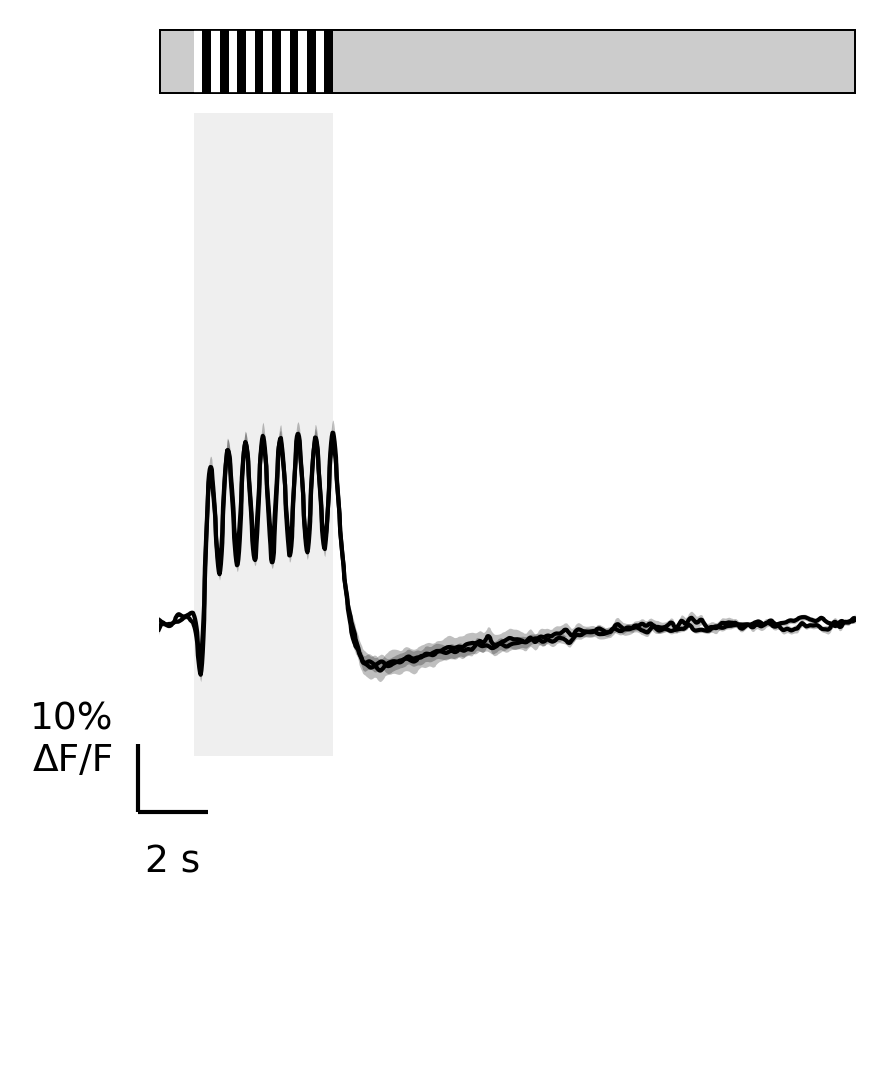

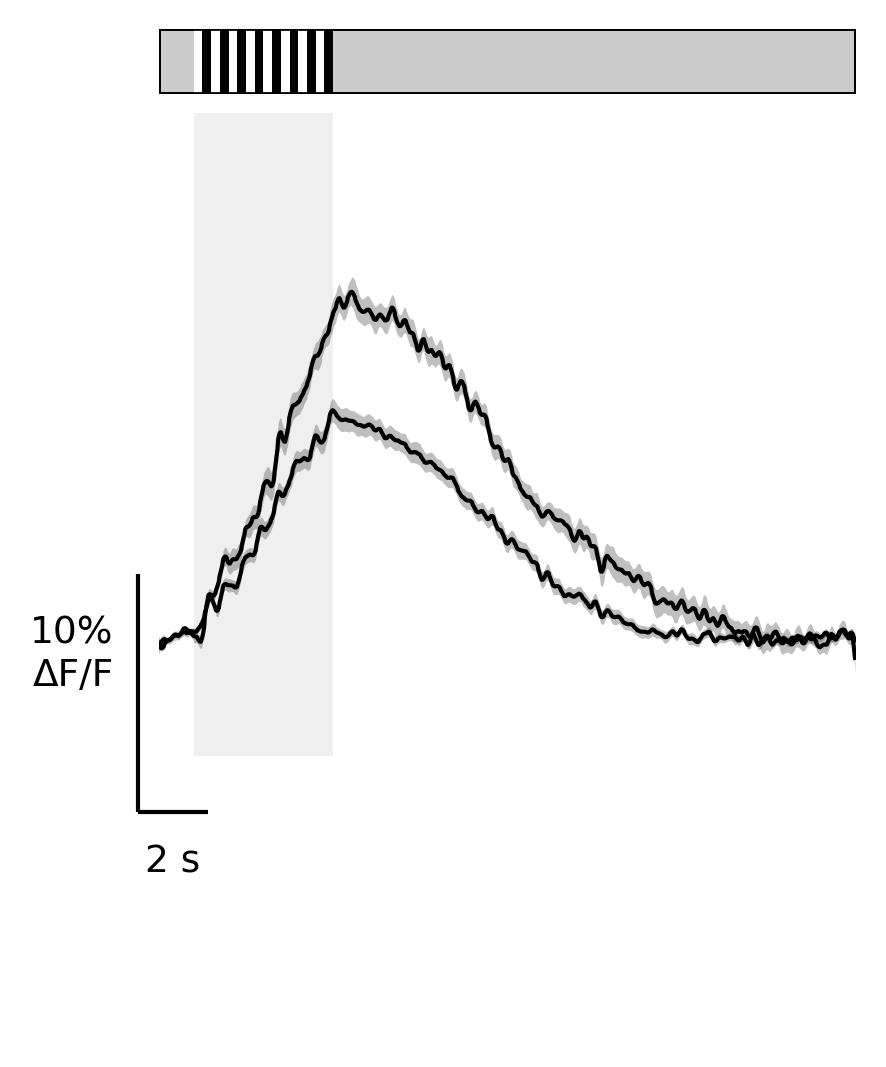

In [33]:
plot_genotypes_overlay_compactstyle(
    all_data=select_genotypes(all_data, GENOTYPES_TO_PLOT),
    compartment="m9",
    meas_type="ca",
    lowpass_cutoff_hz=4.0,   # for example 4.0 to match the tPeak and AUC analysis
    grid_step="20ms",
    colors=genotype_colors_ca,
    figsize=(3, 4),
    stim_type="20xflicker",      # or "300msdark", "300mslight"
    stim_start=1.0,
    xlim=(0, 20),
    ylim=(-0.2, 0.75),
    df_over_f_scale=0.1,
    time_scale=2,
    line_width=1.0,
    add_stim_background=True,
    
    stim_background_color="0.88",
    stim_background_alpha=0.5,
)

plot_genotypes_overlay_compactstyle(
    all_data=select_genotypes(all_data, GENOTYPES_TO_PLOT),
    compartment="m9",
    meas_type="hylight",
    lowpass_cutoff_hz=4.0,   # for example 4.0 to match the tPeak and AUC analysis
    grid_step="20ms",
    colors=genotype_colors_hylight,
    figsize=(3, 4),
    stim_type="20xflicker",      # or "300msdark", "300mslight"
    stim_start=1.0,
    xlim=(0, 20),
    ylim=(-0.05, 0.22),
    df_over_f_scale=0.10,
    time_scale=2,
    line_width=1.0,
    add_stim_background=True,
    
    stim_background_color="0.88",
    stim_background_alpha=0.5,
)